# Example 9.3 — Post-Optimization Analysis

**Chapter 9: Step-by-Step Trajectory Synthesis**

Evaluates the optimal mechanism: checks Grashof, calculates the transmission angle profile and compares it with the desired trajectory.

## 1. Parameters of the optimal mechanism

In [11]:
from numpy import *

r1 = 82.41
r2 = 38.67
r3 = 103.21
r4 = 91.08

xp_opt = 28.93
yp_opt = -12.47
theta20 = 14.32

print('Optimal mechanism found by the GA:')
print(f'  r1={r1} mm,  r2={r2} mm')
print(f'  r3={r3} mm,  r4={r4} mm')
print(f'  Coupler: xp={xp_opt} mm, yp={yp_opt} mm')
print(f'  Initial angle θ₂₀={theta20}°')

Optimal mechanism found by the GA:
  r1=82.41 mm,  r2=38.67 mm
  r3=103.21 mm,  r4=91.08 mm
  Coupler: xp=28.93 mm, yp=-12.47 mm
  Initial angle θ₂₀=14.32°


## 2. Grashof Verification

In [12]:
from numpy import *

longs = array([r1, r2, r3, r4])
s = min(longs)
l = max(longs)

resto = sorted(longs)[1:3]
p = resto[0]
q = resto[1]

grashof = (s + l) < (p + q)

print('=== Grashof Condition ===')
print(f'  s (minimum) = {s:.2f} mm')
print(f'  l (maximum) = {l:.2f} mm')
print(f'  p = {p:.2f} mm,  q = {q:.2f} mm')
print(f'  s+l = {s+l:.2f} mm,  p+q = {p+q:.2f} mm')
print(f'  Grashof: {"SATISFIED" if grashof else "NOT SATISFIED"}')

=== Grashof Condition ===
  s (minimum) = 38.67 mm
  l (maximum) = 103.21 mm
  p = 82.41 mm,  q = 91.08 mm
  s+l = 141.88 mm,  p+q = 173.49 mm
  Grashof: SATISFIED


## 3. Analysis of Transmission Angle

In [13]:
from numpy import *

def analizar(r1, r2, r3, r4, t2):
    A = 2 * r4 * (r1 - r2 * cos(t2))
    B = -2 * r2 * r4 * sin(t2)
    C = r1**2 + r2**2 + r4**2 - r3**2 - 2 * r1 * r2 * cos(t2)
    d = A**2 + B**2 - C**2

    if d < 0:
        return None, None

    t4 = 2 * arctan2(-B + sqrt(d), A - C)
    t3 = arctan2(
        (r4 * sin(t4) - r2 * sin(t2)) / r3,
        (r1 + r4 * cos(t4) - r2 * cos(t2)) / r3
    )
    return t3, t4

t2_arr = linspace(radians(theta20), radians(theta20) + 2 * pi, 360)
mu_arr = []
ok = 0

for t2 in t2_arr:
    t3, t4 = analizar(r1, r2, r3, r4, t2)
    if t3 is not None:
        mu = degrees(abs(t3 - t4)) % 180
        if mu > 90:
            mu = 180 - mu
        mu_arr.append(mu)
        if 40 <= mu <= 140:
            ok += 1

mu_arr = array(mu_arr)
pct = 100.0 * ok / 360

print('=== Transmission Angle ===')
print(f'  Minimum μ:   {min(mu_arr):.2f}°')
print(f'  Maximum μ:   {max(mu_arr):.2f}°')
print(f'  Average μ:   {mean(mu_arr):.2f}°')
print(f'  % in optimal zone [40°,140°]: {pct:.1f}%')

=== Transmission Angle ===
  Minimum μ:   17.35°
  Maximum μ:   89.85°
  Average μ:   50.74°
  % in optimal zone [40°,140°]: 55.8%


## 4. Comparison of Desired vs. Obtained Trajectory

In [14]:
from numpy import *

N_PUNTOS = 20
t = linspace(0, 2 * pi, N_PUNTOS, endpoint=False)
fac = 1 - 0.5 * sin(t / 2)
xd = 100 + 50 * cos(t) * fac
yd = 100 + 50 * sin(t) * fac

t2_pts = linspace(radians(theta20), radians(theta20) + 2 * pi, N_PUNTOS, endpoint=False)
xa_arr = []
ya_arr = []
err_arr = []

for i, t2 in enumerate(t2_pts):
    t3, t4 = analizar(r1, r2, r3, r4, t2)
    if t3 is not None:
        xa = r2 * cos(t2) + xp_opt * cos(t3) - yp_opt * sin(t3)
        ya = r2 * sin(t2) + xp_opt * sin(t3) + yp_opt * cos(t3)
        xa_arr.append(xa)
        ya_arr.append(ya)
        err_arr.append(sqrt((xa - xd[i])**2 + (ya - yd[i])**2))

print(f'Mean error:  {mean(err_arr):.4f} mm')
print(f'Max error: {max(err_arr):.4f} mm')

Mean error:  115.7916 mm
Max error: 127.4034 mm


## 5. Visualizing Post-Optimization Analysis

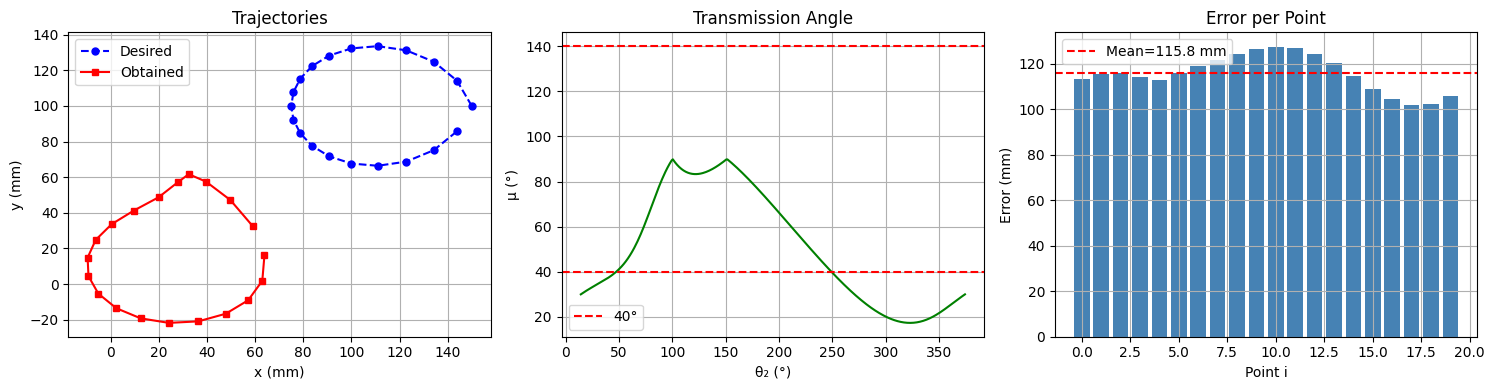

In [15]:
import matplotlib.pyplot as plt
from numpy import *

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Subplot 1: Trajectories
axes[0].plot(xd, yd, 'b--o', ms=5, label='Desired')
axes[0].plot(xa_arr, ya_arr, 'r-s', ms=5, label='Obtained')
axes[0].set_title('Trajectories')
axes[0].legend()
axes[0].grid(True)
axes[0].set_xlabel('x (mm)')
axes[0].set_ylabel('y (mm)')

# Subplot 2: Transmission Angle
t2d = degrees(t2_arr)
axes[1].plot(t2d[:len(mu_arr)], mu_arr, 'g-')
axes[1].axhline(40, color='r', ls='--', label='40°')
axes[1].axhline(140, color='r', ls='--')
axes[1].set_title('Transmission Angle')
axes[1].legend()
axes[1].grid(True)
axes[1].set_xlabel('θ₂ (°)')
axes[1].set_ylabel('μ (°)')

# Subplot 3: Error per Point
axes[2].bar(range(len(err_arr)), err_arr, color='steelblue')
axes[2].axhline(mean(err_arr), color='r', ls='--', label=f'Mean={mean(err_arr):.1f} mm')
axes[2].set_title('Error per Point')
axes[2].legend()
axes[2].grid(True)
axes[2].set_xlabel('Point i')
axes[2].set_ylabel('Error (mm)')

plt.tight_layout()
plt.savefig('analisis_postoptimizacion.png', dpi=150, bbox_inches='tight')
plt.show()